In [2]:
import pandas as pd
import matplotlib.pyplot as plt # viz
import seaborn as sns # better viz
import numpy as np # numerical python

reading the csv file from the folder

In [3]:
df = pd.read_csv("./dataset/amz_uk_price_prediction_dataset.csv")

want to know the first informations about the columns

In [30]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


want to know how big the file is

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


still not clear for me: whether any column missing. Thus print out the rows and columns

In [32]:
num_rows, num_cols = df.shape

print(f'Rows: {num_rows}, Columns: {num_cols}')

Rows: 2443651, Columns: 9


As this is a big data set, divided into number and non-number colums. This is for safty, until unless required we will use the main data frame: df

In [33]:
num = df.select_dtypes(include="number")
cat = df.select_dtypes(exclude="number")
cat

,asin,title,isBestSeller,category
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",True,Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",False,Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,False,Hi-Fi Speakers
...,...,...,...,...
2443646,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",False,Motorbike Clothing
2443647,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,False,Motorbike Clothing
2443648,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,False,Motorbike Clothing
2443649,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,False,Motorbike Clothing


### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    

In [34]:
category_counts = df['category'].value_counts().reset_index()
category_counts.columns = ["category", "frequency"]
category_counts

,category,frequency
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978
...,...,...
291,Alexa Built-In Devices,107
292,Motorbike Chassis,107
293,Plugs,107
294,Smart Home Security & Lighting,104


    - Which are the top 5 most listed product categories?   

In [35]:
category_counts.head(5)

,category,frequency
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


**Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [36]:
top_category = category_counts.head(5)

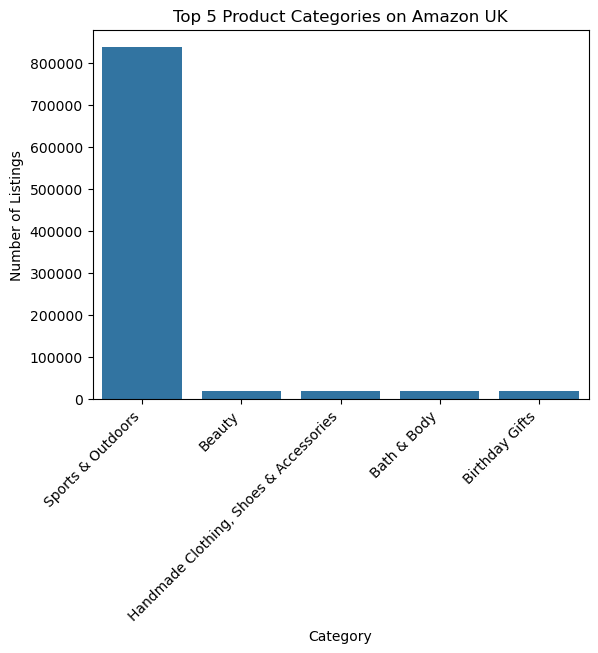

In [43]:
sns.barplot(x='category', y='frequency', data=top_category)
#plt.yscale('log')
plt.xticks(rotation=45, ha='right')
plt.title('Top 5 Product Categories on Amazon UK')
plt.xlabel('Category')
plt.ylabel('Number of Listings')
plt.show()


### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?




In [46]:
print(df["price"].mean())
print(df["price"].median())
print(df["price"].mode())

89.24380943923661
19.09
0    9.99
Name: price, dtype: float64


Average (Mean) Price: 89.24
Most Common Price (Mode): 9.99
This means that maximum product listed in the data set is below 10 and few items are outline and very expensive which lead the mean value to 90.



2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?


In [58]:
Variance = df["price"].var()
Standard_deviation = df["price"].std()
Range = df["price"].max()- df["price"].min()
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
interquartile_range = q3 - q1

print(f"variance: {Variance}")
print(f"Standard_deviation: {Standard_deviation}")
print(f"Range: {Range}")
print(f"interquartile_range: {interquartile_range}")


variance: 119445.4853225653
Standard_deviation: 345.6088617535223
Range: 100000.0
interquartile_range: 36.0


3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

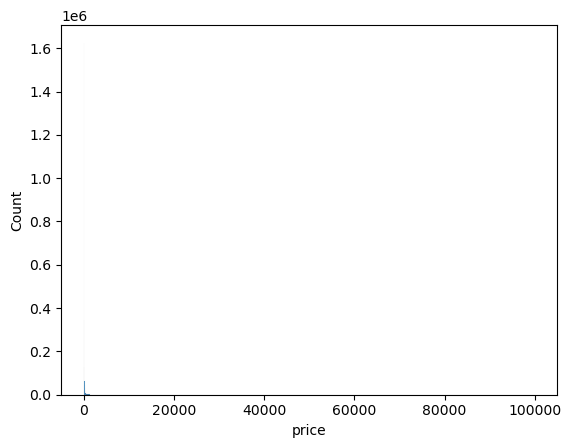

In [59]:
sns.histplot(df['price'], bins="auto")
plt.show()

In the plot close to 0 a very thin line exist. this is because maximum products are close to zero (actually close to 10 from mode value). And very few items are there which is costing 100000.
Solution: we may need to trancate the data may be below 100 to check if this gives a better distribution plot.

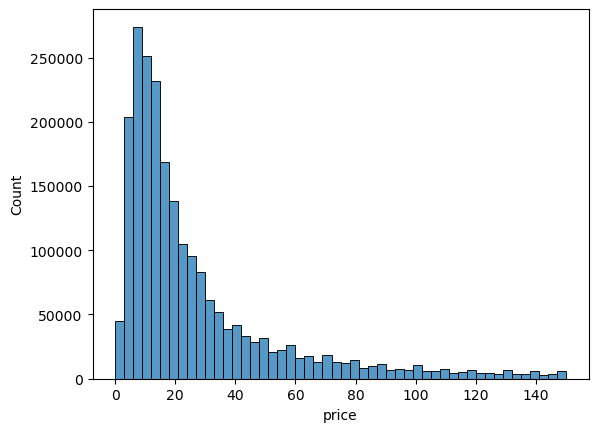

In [61]:
sns.histplot(df[df['price'] <= 150]['price'], bins=50)
plt.show()

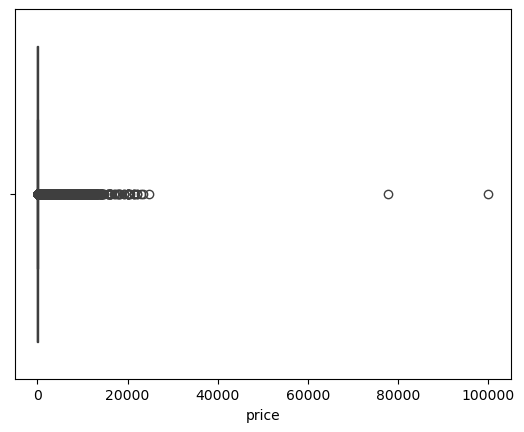

In [62]:
sns.boxplot(x='price', data=df)
plt.show()

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [67]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [69]:
mean_rating = df["stars"].mean()
median_rating = df["stars"].median()
mode_rating = df["stars"].mode()

print(f"Mean Rating: {mean_rating}")
print(f"Median Rating: {median_rating}")
print(f"Mode Rating: {mode_rating}")

Mean Rating: 2.152836472966066
Median Rating: 0.0
Mode Rating: 0    0.0
Name: stars, dtype: float64


Although the mean rating is 2.15 the mode rating (most common) is 0, which means that losts of product got rating 0, which outperform the avgerage value.

In [70]:
Variance = df["stars"].var()
Standard_deviation = df["stars"].std()
Range = df["stars"].max()- df["stars"].min()
q1 = df['stars'].quantile(0.25)
q3 = df['stars'].quantile(0.75)
interquartile_range = q3 - q1

print(f"variance: {Variance}")
print(f"Standard_deviation: {Standard_deviation}")
print(f"Range: {Range}")
print(f"interquartile_range: {interquartile_range}")

variance: 4.81743402976196
Standard_deviation: 2.1948653785054697
Range: 5.0
interquartile_range: 4.4


There is wide variation in customer feedback

In [71]:
skew_rating = df['stars'].skew()
kurt_rating = df['stars'].kurt()
print(f"Skewness: {skew_rating}")
print(f"Kurtosis: {kurt_rating}")

Skewness: 0.08120735761080881
Kurtosis: -1.9260061280432994


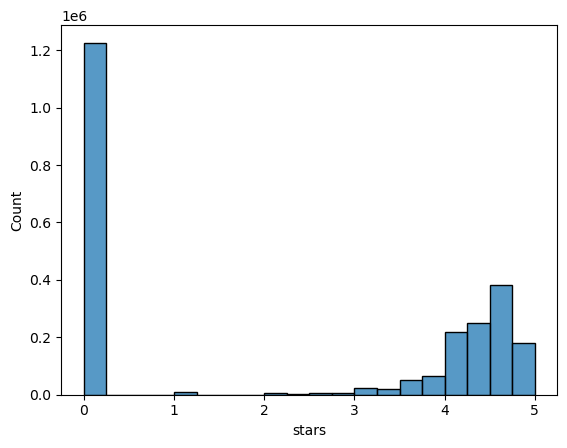

In [72]:
sns.histplot(df['stars'], bins=20)
plt.show()

Zero rating is more common compared to others.

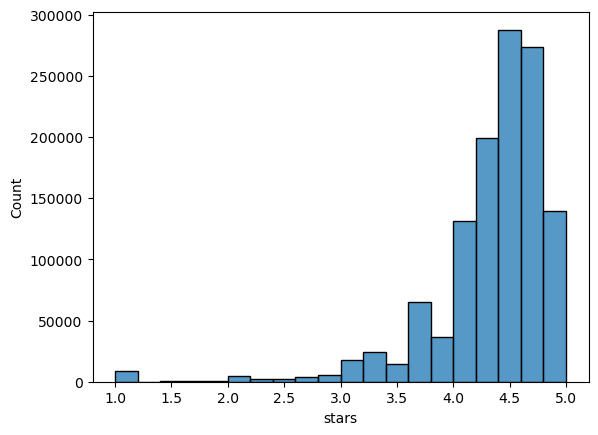

In [75]:

sns.histplot(df[df['stars']>0]['stars'], bins=20)
plt.show()